# Super-Earths and Potentially Habitable Exoplanets

Analysis of Super-Earth candidates (R < 2.5 Re) and habitable zone planets.
Includes atmospheric escape, oxygen biosignature detectability, and HZ boundaries.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, '/home/dawe/Projects/astro-science/research/projects/exoplanets')
from models.super_earth import *
from models.equations import habitable_zone_distances, equilibrium_temperature, scale_height

BASE = '/home/dawe/Projects/astro-science/research/projects/exoplanets'
hz = pd.read_csv(f'{BASE}/data/processed/super_earths_hz.csv')
allp = pd.read_csv(f'{BASE}/data/processed/super_earths_all.csv')
print(f'HZ candidates: {len(hz)}')
print(f'All small planets (R<2.5 Re): {len(allp)}')


HZ candidates: 45
All small planets (R<2.5 Re): 2466


## 1. HZ candidate overview

In [2]:
print(hz[['pl_name', 'hostname', 'sy_dist', 'pl_rade', 'pl_eqt', 'pl_orbper', 'st_teff']].to_string(index=False))


      pl_name    hostname  sy_dist  pl_rade  pl_eqt  pl_orbper  st_teff
  Kepler-22 b   Kepler-22 194.6420    2.100  279.00 289.863876   5596.0
 Kepler-138 d  Kepler-138  66.8624    1.510  345.00  23.092300   3841.0
  Kepler-61 b   Kepler-61 335.0790    2.150  273.00  59.877560   4017.0
  Kepler-62 e   Kepler-62 300.8740    1.610  270.00 122.387400   4925.0
Kepler-1652 b Kepler-1652      NaN    1.600  268.00  38.097220   3638.0
  Kepler-69 c   Kepler-69 730.6250    1.710  299.00 242.461300   5638.0
  Kepler-62 f   Kepler-62 300.8740    1.410  208.00 267.291000   4925.0
Kepler-1653 b Kepler-1653      NaN    2.170  284.00 140.252400   4807.0
Kepler-1649 b Kepler-1649  92.1913    1.017  307.00   8.689099   3240.0
 Kepler-452 b  Kepler-452 551.7270    1.630  265.00 384.843000   5757.0
Kepler-1649 c Kepler-1649  92.1913    1.060  234.00  19.535270   3240.0
       K2-3 d        K2-3  44.0727    1.458  305.20  44.556030   3844.0
       K2-9 b        K2-9  82.9631    2.250  314.00  18.449800  

## 2. Radius vs equilibrium temperature

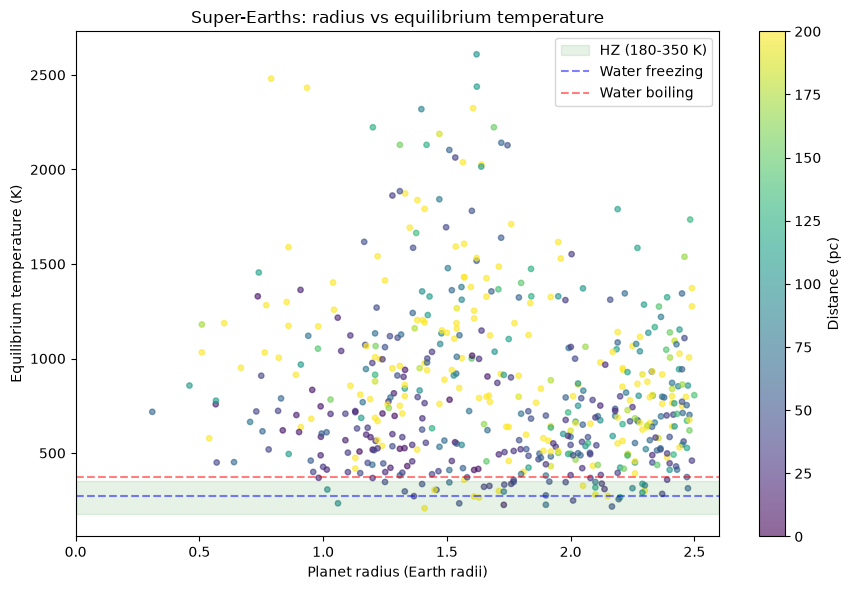

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(allp['pl_rade'], allp['pl_eqt'], c=allp['sy_dist'], cmap='viridis',
                s=15, alpha=0.6, vmin=0, vmax=200)
ax.axhspan(180, 350, alpha=0.1, color='green', label='HZ (180-350 K)')
ax.axhline(273, color='blue', linestyle='--', alpha=0.5, label='Water freezing')
ax.axhline(373, color='red', linestyle='--', alpha=0.5, label='Water boiling')
ax.set_xlabel('Planet radius (Earth radii)')
ax.set_ylabel('Equilibrium temperature (K)')
ax.set_title('Super-Earths: radius vs equilibrium temperature')
ax.set_xlim(0, 2.6)
ax.legend(loc='upper right')
plt.colorbar(sc, label='Distance (pc)')
plt.tight_layout(); plt.show()


## 3. Atmospheric retention analysis

For each HZ candidate, check if O2, N2, H2O, CO2 are retained.

In [4]:
results = []
for _, p in hz.iterrows():
    M = p['pl_bmasse'] if pd.notna(p['pl_bmasse']) else p['pl_rade']**2.8  # mass-radius if no mass
    R = p['pl_rade']
    Teq = p['pl_eqt']
    for sp in ['O2', 'N2', 'H2O', 'CO2', 'H2']:
        r = atmospheric_retention(M, R, Teq, sp)
        results.append({'planet': p['pl_name'], 'species': sp, 'jeans_lambda': r['jeans_lambda'], 'retained': r['retained']})
rdf = pd.DataFrame(results)
print(rdf.groupby('species')['retained'].agg(['sum', 'count']))
print()
print('Planets retaining O2:')
o2 = rdf[(rdf['species']=='O2') & (rdf['retained'])]
print(o2['planet'].tolist())


         sum  count
species            
CO2       45     45
H2        45     45
H2O       45     45
N2        45     45
O2        45     45

Planets retaining O2:
['Kepler-22 b', 'Kepler-138 d', 'Kepler-61 b', 'Kepler-62 e', 'Kepler-1652 b', 'Kepler-69 c', 'Kepler-62 f', 'Kepler-1653 b', 'Kepler-1649 b', 'Kepler-452 b', 'Kepler-1649 c', 'K2-3 d', 'K2-9 b', 'K2-18 b', 'LHS 1140 b', 'K2-152 b', 'K2-286 b', 'K2-288 B b', 'K2-133 e', 'K2-323 b', 'TOI-1266 c', 'K2-332 b', 'TOI-2257 b', 'TOI-712 d', 'TOI-1452 b', 'LP 890-9 c', 'TOI-1468 c', 'TOI-2096 c', 'Kepler-1126 c', 'Kepler-1052 c', 'Kepler-311 d', 'TOI-715 b', 'TOI-2095 b', 'TOI-2095 c', 'TOI-904 c', 'TOI-4336 A b', 'TOI-6002 b', 'TOI-5713 b', 'TOI-5799 c', 'TOI-2093 c', 'TOI-7166 b', 'LHS 1903 e', 'TOI-2094 b', 'TOI-1752 c', 'TOI-789 d']


## 4. Oxygen biosignature detectability

For each HZ candidate with retained O2, estimate transit depth and detectability.

In [5]:
det = []
for _, p in hz.iterrows():
    M = p['pl_bmasse'] if pd.notna(p['pl_bmasse']) else p['pl_rade']**2.8
    R = p['pl_rade']
    Teq = p['pl_eqt']
    # Estimate scale height for O2 atmosphere
    g = (M * 5.972e24 * 6.674e-11) / (R * 6.371e6)**2
    H = scale_height(Teq, 32, g)  # O2 mean molecular weight
    # Transit depth variation ~ 2 R_p H / R_star^2 (approximate)
    depth = 2 * (R * 6.371e6) * H / (p['st_rad'] * 6.957e8)**2 if pd.notna(p['st_rad']) else np.nan
    det.append({'planet': p['pl_name'], 'R': R, 'Teq': Teq, 'scale_height_km': H/1000, 'transit_depth': depth,
               'detectable_5sig': biosignature_detectability(10, depth, 10) if pd.notna(depth) else False})
ddf = pd.DataFrame(det)
print(ddf.sort_values('transit_depth', ascending=False).head(15).to_string(index=False))


       planet     R   Teq  scale_height_km  transit_depth  detectable_5sig
 TOI-4336 A b 2.137 309.4        11.146278       0.000006            False
   TOI-2096 c 1.914 349.0         5.454019       0.000005            False
   TOI-6002 b 1.650 321.4         5.655923       0.000004            False
   TOI-7166 b 2.010 249.0         3.741857       0.000004            False
   TOI-1468 c 2.126 338.1         9.791124       0.000004            False
Kepler-1649 b 1.017 307.0         7.956578       0.000004            False
   TOI-1266 c 1.980 346.0        11.240664       0.000003            False
   LHS 1140 b 1.730 226.0         3.172907       0.000003            False
    TOI-715 b 1.550 234.0         4.329076       0.000003            False
Kepler-1649 c 1.060 234.0         5.866997       0.000003            False
   TOI-5713 b 1.770 347.2         5.776248       0.000003            False
   TOI-1452 b 1.672 326.0         4.966928       0.000003            False
     K2-332 b 2.200 266.0

## 5. Tidal locking

HZ planets around M-dwarfs are often tidally locked. Check locking timescales.

In [6]:
lock = []
for _, p in hz.iterrows():
    M = p['pl_bmasse'] if pd.notna(p['pl_bmasse']) else p['pl_rade']**2.8
    a = p['pl_orbsmax'] * 1.496e11 if pd.notna(p['pl_orbsmax']) else np.nan
    if pd.isna(a): 
        continue
    tau = tidal_locking_timescale(a, p['st_mass']*1.989e30 if pd.notna(p['st_mass']) else 1.989e30,
                                  M*5.972e24, p['pl_rade']*6.371e6)
    lock.append({'planet': p['pl_name'], 'period_d': p['pl_orbper'], 'lock_Gyr': tau, 'locked': tau < 1.0})
ldf = pd.DataFrame(lock)
print(f'Tidally locked (tau < 1 Gyr): {ldf["locked"].sum()} / {len(ldf)}')
print(ldf[ldf['locked']].head(10).to_string(index=False))


Tidally locked (tau < 1 Gyr): 41 / 41
       planet   period_d     lock_Gyr  locked
  Kepler-22 b 289.863876 9.551766e-03    True
 Kepler-138 d  23.092300 2.030993e-06    True
  Kepler-62 e 122.387400 1.176374e-03    True
Kepler-1652 b  38.097220 1.195793e-05    True
  Kepler-69 c 242.461300 7.160360e-03    True
  Kepler-62 f 267.291000 5.161293e-02    True
Kepler-1653 b 140.252400 4.364763e-04    True
 Kepler-452 b 384.843000 1.058035e-01    True
       K2-3 d  44.556030 3.359155e-05    True
       K2-9 b  18.449800 1.093702e-07    True


## 6. Summary: most promising Super-Earth candidates

Planets that are: in HZ, retain O2, potentially detectable.

In [7]:
print('Most promising candidates for oxygen biosignature search:')
for _, p in hz.nsmallest(10, 'pl_rade').iterrows():
    M = p['pl_bmasse'] if pd.notna(p['pl_bmasse']) else p['pl_rade']**2.8
    print(f"  {p['pl_name']:20s} R={p['pl_rade']:.2f} Re  Teq={p['pl_eqt']:.0f}K  d={p['sy_dist']:.1f} pc  host={p['hostname']}")


Most promising candidates for oxygen biosignature search:
  Kepler-1649 b        R=1.02 Re  Teq=307K  d=92.2 pc  host=Kepler-1649
  Kepler-1649 c        R=1.06 Re  Teq=234K  d=92.2 pc  host=Kepler-1649
  TOI-2095 b           R=1.25 Re  Teq=347K  d=41.9 pc  host=TOI-2095
  TOI-2095 c           R=1.33 Re  Teq=297K  d=41.9 pc  host=TOI-2095
  LP 890-9 c           R=1.37 Re  Teq=272K  d=32.4 pc  host=LP 890-9
  TOI-789 d            R=1.40 Re  Teq=336K  d=43.4 pc  host=TOI-789
  Kepler-62 f          R=1.41 Re  Teq=208K  d=300.9 pc  host=Kepler-62
  Kepler-1126 c        R=1.45 Re  Teq=305K  d=635.7 pc  host=Kepler-1126
  K2-3 d               R=1.46 Re  Teq=305K  d=44.1 pc  host=K2-3
  Kepler-138 d         R=1.51 Re  Teq=345K  d=66.9 pc  host=Kepler-138
